# Practical 5: Decision Trees and SVM Classification
**Project:** Groundwater Level Prediction & Risk Classification

**Input files:** `03_wells_with_risk.csv` (Practical 3) and `05_knn_nb_results.csv` (Practical 4)
**Output file:** `06_classification_results.csv` (all classification models together)

**Aim:** build a **Decision Tree** (with readable rules) and a **Support Vector Machine** to predict the 2022 risk class, then compare them with the KNN and Naive Bayes results from Practical 4.

## Step 1: Load the data and the saved train/test split
**What to say:** *Same file and same split as Practical 4, so the new models are tested on exactly the same hidden wells and the comparison is fair.*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("03_wells_with_risk.csv")

features = ["Latitude", "Longitude", "Well_Depth (meters)", "pre_mean", "post_mean", "recharge", "change", "Pre_2021"]
labels = ["Safe", "Watch", "Critical", "Severe"]          # risk codes 0, 1, 2, 3

train = df[df["set"] == "train"]
test = df[df["set"] == "test"]

X_train, X_test = train[features], test[features]
y_train, y_test = train["risk_code"], test["risk_code"]

print("Training wells:", len(train), "| Test wells:", len(test))

Training wells: 1478 | Test wells: 370


## Step 2: Scale the features (for SVM)
**What to say:** *SVM uses distances, so I scale the features, fitting the scaler on training wells only. Decision Trees ask yes/no questions about one feature at a time, so they do not need scaling.*

In [2]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Step 3: Evaluation function
**What to say:** *The same function as in Practical 4: accuracy, precision, recall, F1 (averaged over the four classes), log loss, AUC, and at-risk recall, which is the share of truly Critical or Severe wells that were caught.*

In [3]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             log_loss, roc_auc_score, ConfusionMatrixDisplay)

results = []
predictions = {}

def evaluate(name, pred, proba):
    results.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred, average="macro"),
                    "Recall": recall_score(y_test, pred, average="macro"),
                    "F1": f1_score(y_test, pred, average="macro"),
                    "At-risk recall": recall_score(y_test >= 2, pred >= 2),
                    "Log loss": log_loss(y_test, proba),
                    "AUC": roc_auc_score(y_test, proba, multi_class="ovr")})
    predictions[name] = pred

## Step 4: Decision Tree
**What to say:** *A decision tree asks a series of yes/no questions about the features, like a flow chart, until it reaches a class. I limited the depth to 4 so the tree stays readable and does not simply memorise the training wells.*

In [4]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)

evaluate("Decision Tree", tree.predict(X_test), tree.predict_proba(X_test))
pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,At-risk recall,Log loss,AUC
0,Decision Tree,0.897,0.897,0.906,0.9,0.972,0.474,0.97


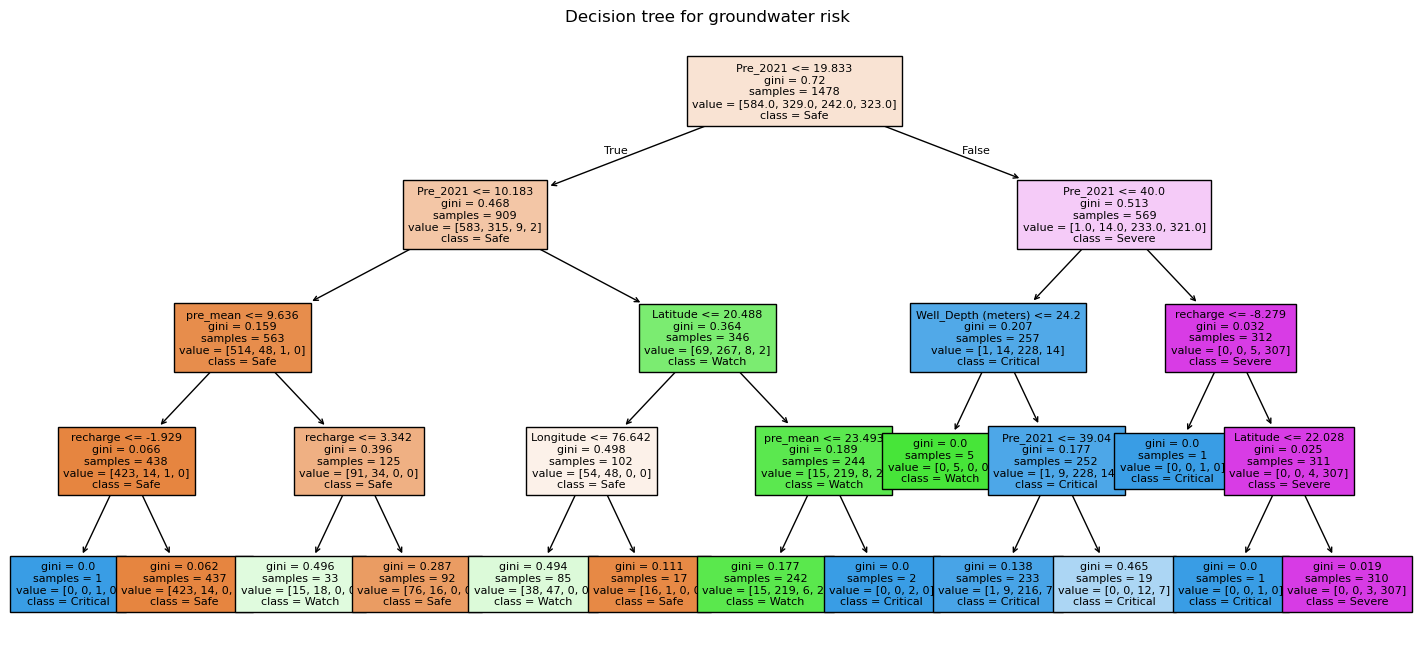

In [5]:
plt.figure(figsize=(18, 8))
plot_tree(tree, feature_names=features, class_names=labels, filled=True, fontsize=8)
plt.title("Decision tree for groundwater risk")
plt.show()

### The tree as rules
**What to say:** *A tree can be read as IF-THEN rules. Each line is one question, and 'class' at the end of a branch is the final answer. This is the big advantage of decision trees: I can explain every prediction.*

In [6]:
print(export_text(tree, feature_names=features, class_names=labels))

|--- Pre_2021 <= 19.83
|   |--- Pre_2021 <= 10.18
|   |   |--- pre_mean <= 9.64
|   |   |   |--- recharge <= -1.93
|   |   |   |   |--- class: Critical
|   |   |   |--- recharge >  -1.93
|   |   |   |   |--- class: Safe
|   |   |--- pre_mean >  9.64
|   |   |   |--- recharge <= 3.34
|   |   |   |   |--- class: Watch
|   |   |   |--- recharge >  3.34
|   |   |   |   |--- class: Safe
|   |--- Pre_2021 >  10.18
|   |   |--- Latitude <= 20.49
|   |   |   |--- Longitude <= 76.64
|   |   |   |   |--- class: Watch
|   |   |   |--- Longitude >  76.64
|   |   |   |   |--- class: Safe
|   |   |--- Latitude >  20.49
|   |   |   |--- pre_mean <= 23.49
|   |   |   |   |--- class: Watch
|   |   |   |--- pre_mean >  23.49
|   |   |   |   |--- class: Critical
|--- Pre_2021 >  19.83
|   |--- Pre_2021 <= 40.00
|   |   |--- Well_Depth (meters) <= 24.20
|   |   |   |--- class: Watch
|   |   |--- Well_Depth (meters) >  24.20
|   |   |   |--- Pre_2021 <= 39.04
|   |   |   |   |--- class: Critical
|   |   | 

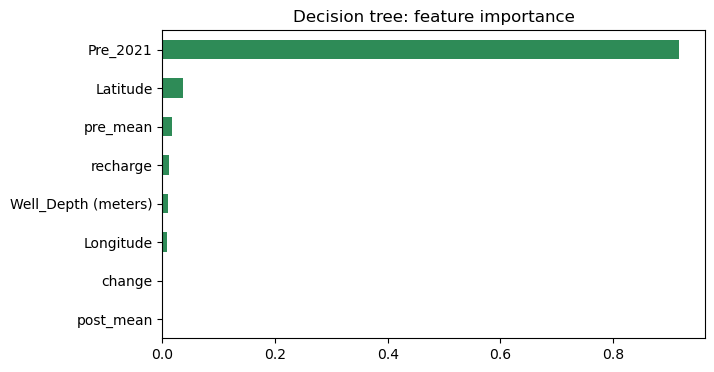

In [7]:
# Which features did the tree use most?
importance = pd.Series(tree.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", figsize=(7, 4), color="seagreen")
plt.title("Decision tree: feature importance")
plt.show()

## Step 5: Support Vector Machine (SVM)
**What to say:** *SVM draws the boundary that separates the classes with the widest possible gap. A linear kernel uses straight boundaries. The RBF kernel allows curved boundaries. I try both.*

In [8]:
from sklearn.svm import SVC

svm_linear = SVC(kernel="linear", probability=True, random_state=42)
svm_linear.fit(X_train_s, y_train)
evaluate("SVM (linear)", svm_linear.predict(X_test_s), svm_linear.predict_proba(X_test_s))

svm_rbf = SVC(kernel="rbf", probability=True, random_state=42)
svm_rbf.fit(X_train_s, y_train)
evaluate("SVM (RBF)", svm_rbf.predict(X_test_s), svm_rbf.predict_proba(X_test_s))

pd.DataFrame(results).round(3)

,Model,Accuracy,Precision,Recall,F1,At-risk recall,Log loss,AUC
0,Decision Tree,0.897,0.897,0.906,0.900,0.972,0.474,0.970
1,SVM (linear),0.862,0.860,0.854,0.855,0.972,0.302,0.981
2,SVM (RBF),0.843,0.845,0.830,0.836,0.950,0.335,0.974


## Step 6: Compare all classification models and save
**What to say:** *I add the new models to the table saved in Practical 4, so now all models are in one table. All numbers are on test wells that no model saw during training.*

In [9]:
earlier = pd.read_csv("05_knn_nb_results.csv")               # baseline, KNN, Naive Bayes
all_results = pd.concat([earlier, pd.DataFrame(results).round(3)], ignore_index=True)

print(all_results.to_string(index=False))

all_results.to_csv("06_classification_results.csv", index=False)
print("Saved 06_classification_results.csv")

               Model  Accuracy  Precision  Recall    F1  At-risk recall  Log loss   AUC
Baseline (2021 rule)     0.897      0.900   0.905 0.902           0.979       NaN   NaN
                 KNN     0.805      0.806   0.781 0.792           0.901     0.773 0.952
         Naive Bayes     0.824      0.819   0.814 0.812           0.950     0.827 0.969
       Decision Tree     0.897      0.897   0.906 0.900           0.972     0.474 0.970
        SVM (linear)     0.862      0.860   0.854 0.855           0.972     0.302 0.981
           SVM (RBF)     0.843      0.845   0.830 0.836           0.950     0.335 0.974
Saved 06_classification_results.csv


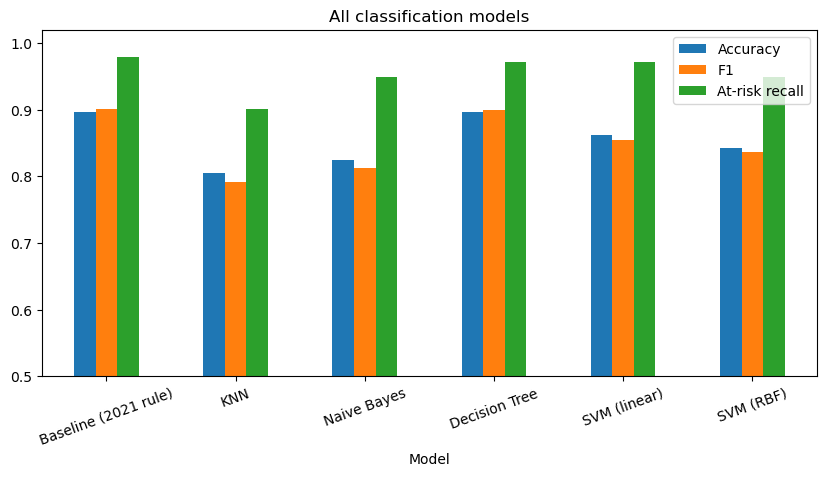

In [10]:
all_results.plot(x="Model", y=["Accuracy", "F1", "At-risk recall"], kind="bar", figsize=(10, 4.5))
plt.ylim(0.5, 1.02)
plt.xticks(rotation=20)
plt.title("All classification models")
plt.show()

## Step 7: Confusion matrices
**What to say:** *Rows are the true class and columns are the predicted class. The diagonal holds the correct answers. Mistakes mostly sit next to the diagonal, meaning neighbouring classes get mixed up.*

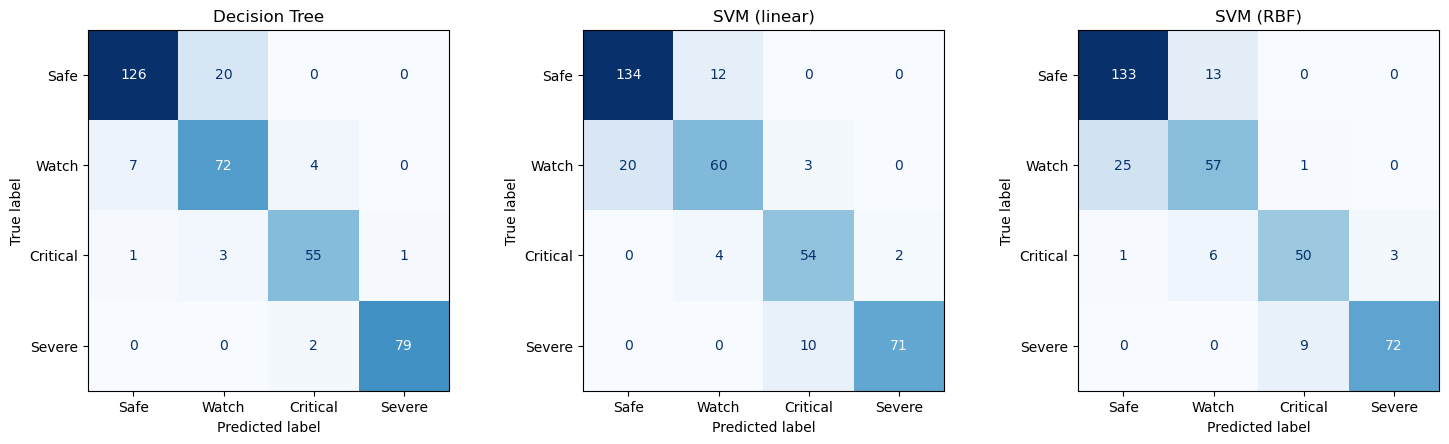

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, ["Decision Tree", "SVM (linear)", "SVM (RBF)"]):
    ConfusionMatrixDisplay.from_predictions(y_test, predictions[name], display_labels=labels,
                                            ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Step 8: ROC curve for the 'at risk' question
**What to say:** *The ROC curve shows the trade-off between catching at-risk wells (up) and raising false alarms (right). The closer the curve is to the top-left corner, and the larger the area under it (AUC), the better. I combine Critical and Severe into one 'at risk' group.*

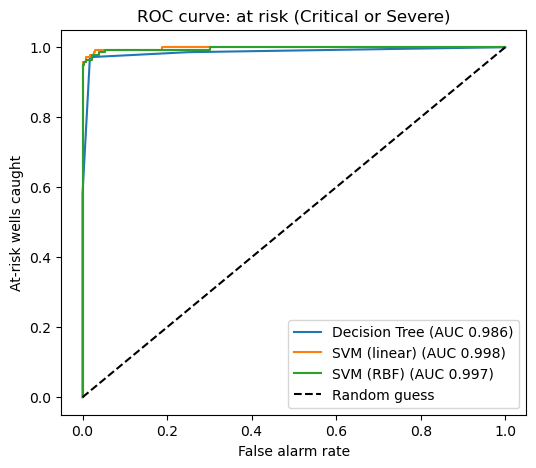

In [12]:
from sklearn.metrics import roc_curve, auc

at_risk_true = (y_test >= 2).astype(int)
models = {"Decision Tree": tree.predict_proba(X_test),
          "SVM (linear)": svm_linear.predict_proba(X_test_s),
          "SVM (RBF)": svm_rbf.predict_proba(X_test_s)}

plt.figure(figsize=(6, 5))
for name, proba in models.items():
    at_risk_score = proba[:, 2] + proba[:, 3]              # probability of Critical or Severe
    fpr, tpr, _ = roc_curve(at_risk_true, at_risk_score)
    plt.plot(fpr, tpr, label=name + " (AUC " + str(round(auc(fpr, tpr), 3)) + ")")
plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False alarm rate")
plt.ylabel("At-risk wells caught")
plt.legend()
plt.title("ROC curve: at risk (Critical or Severe)")
plt.show()

## Conclusion
**What to say:** *Last year's depth is such a strong predictor that a simple rule is hard to beat. The Decision Tree matches it, and has the big advantage that I can explain every decision with readable rules. The SVM gives the best probabilities (lowest log loss and highest AUC). So I would choose the Decision Tree when explanation matters, and the SVM when ranking wells by danger matters.*

---
**Next: Practical 6 (Clustering)**: K-Means and hierarchical clustering of districts, starting from `03_wells_with_risk.csv`.